# AquaSpectra — Reproducible Sentinel-2 Coastal Spectral Change PoC

**Arab Youth Space Hackathon — 813 Challenge | Team AquaSpectra**

This notebook uses **Sentinel-2 Level-2A multispectral** imagery from 29 March, 3 April, 6 April, and 28 April 2023 over Al Raha Bay, Abu Dhabi. It computes a preliminary low-SWIR candidate-water mask, NDCI, 5×5 spatial smoothing, and an exploratory 29 March–3 April change comparison. The highest 10% of eligible change pixels are grouped into candidate monitoring regions.

**Not a harmful algal bloom detector:** These are unvalidated candidate regions, not confirmed blooms or a forecast. No trained ML model or hyperspectral processing is implemented.

**Run:** Install dependencies from the repository's `requirements.txt`, then run cells in order. The notebook reads the committed small `data/sample_input/55.zip` (36 TIFFs nested in four date ZIPs), or downloads that archive from the public project repository when opened independently in Google Colab. Results are written to `results/` if running from a clone, or to a temporary output directory in Colab.


## 1. Imports and data setup — no automatic duplicate extraction

In [4]:
import os, glob, zipfile, pathlib, io, urllib.request
import numpy as np, pandas as pd, rasterio, matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter, label, distance_transform_edt
from rasterio.warp import transform as transform_coords
from IPython.display import display, clear_output

DATES = ['29-03-2023', '03-04-2023', '06-04-2023', '28-04-2023']
BANDS = ['B03','B04','B05','B06','B07','B08','B8A','B11']
REPO_URL = 'https://raw.githubusercontent.com/ayaw269/AquaSpectra/main/data/sample_input/55.zip'
# Works from a cloned repository, from notebooks/, or standalone Google Colab.
candidates = [pathlib.Path.cwd(), pathlib.Path.cwd().parent, pathlib.Path('/content/AquaSpectra')]
repo_root = next((p for p in candidates if (p/'data/sample_input/55.zip').is_file()), None)
if repo_root is None:
    repo_root = pathlib.Path('/content/AquaSpectra') if pathlib.Path('/content').exists() else pathlib.Path.cwd()/'AquaSpectra'
    (repo_root/'data/sample_input').mkdir(parents=True,exist_ok=True)
    zip_path = repo_root/'data/sample_input/55.zip'
    print('Downloading public sample input from GitHub...')
    zip_path = Path("/content/55.zip")
else:
    zip_path = repo_root/'data/sample_input/55.zip'
BASE = str(repo_root/'data/extracted')
pathlib.Path(BASE).mkdir(parents=True,exist_ok=True)

def count_tiffs(base):
    return {d:len(glob.glob(os.path.join(base,d,'**','*.tiff'),recursive=True)) for d in DATES}

if not all(v==9 for v in count_tiffs(BASE).values()):
    with zipfile.ZipFile(zip_path) as outer:
        for date in DATES:
            member = f'55/{date}.zip'
            with zipfile.ZipFile(io.BytesIO(outer.read(member))) as inner:
                target = pathlib.Path(BASE)/date
                target.mkdir(parents=True,exist_ok=True)
                for filename in inner.namelist():
                    if filename.lower().endswith('.tiff') and '/' not in filename and '..' not in filename:
                        (target/filename).write_bytes(inner.read(filename))
assert all(v==9 for v in count_tiffs(BASE).values()), f'Expected 9 TIFFs per date, found {count_tiffs(BASE)}'
print('Loaded sample input:',count_tiffs(BASE))


Loaded sample input: {'29-03-2023': 9, '03-04-2023': 9, '06-04-2023': 9, '28-04-2023': 9}


In [5]:
from pathlib import Path

print(Path("/content/55.zip").exists())

True


## 2. Load spectral bands and verify alignment

In [6]:
data={}; reference_file=None; expected_shape=None; expected_crs=None; expected_transform=None
for date in DATES:
    data[date]={}
    for band in BANDS:
        matches=glob.glob(os.path.join(BASE,date,'**',f'*_{band}_*.tiff'),recursive=True)
        assert len(matches)==1, f'{date} {band}: expected one file, found {len(matches)}'
        with rasterio.open(matches[0]) as src:
            arr=src.read(1).astype('float32')
            if expected_shape is None:
                expected_shape,expected_crs,expected_transform=arr.shape,src.crs,src.transform
            assert arr.shape==expected_shape and src.crs==expected_crs and src.transform==expected_transform, 'Raster grid mismatch'
            data[date][band]=arr
        if date=='03-04-2023' and band=='B03': reference_file=matches[0]
print('Loaded:',len(DATES),'dates; shape:',expected_shape,'CRS:',expected_crs)

Loaded: 4 dates; shape: (96, 166) CRS: EPSG:32640


## 3. Candidate low-SWIR mask and NDCI (not validated water classification)

In [7]:
common_mask=np.ones(expected_shape,dtype=bool)
for date in DATES:
    g,s=data[date]['B03'],data[date]['B11']
    common_mask &= np.isfinite(g)&np.isfinite(s)&(g>0)&(s>=0)&(s<0.03)
ndci_results={}
for date in DATES:
    red,edge=data[date]['B04'],data[date]['B05']
    den=red+edge
    valid=common_mask&np.isfinite(red)&np.isfinite(edge)&(red>0)&(edge>0)&(den>0)
    arr=np.full(expected_shape,np.nan)
    arr[valid]=(edge[valid]-red[valid])/den[valid]
    ndci_results[date]=arr
    print(date,'valid',valid.sum(),'median NDCI',round(float(np.nanmedian(arr)),4))
print('Common candidate pixels:',common_mask.sum())

29-03-2023 valid 4008 median NDCI -0.0177
03-04-2023 valid 4008 median NDCI 0.0726
06-04-2023 valid 3836 median NDCI -0.1417
28-04-2023 valid 4008 median NDCI -0.1953
Common candidate pixels: 4008


## 4. 5×5 moving-window NDCI and temporal change

In [8]:
def moving_window_mean(image, valid_mask, size=5):
    valid=valid_mask&np.isfinite(image)
    sums=uniform_filter(np.where(valid,image,0.0),size=size,mode='constant',cval=0)*size**2
    counts=uniform_filter(valid.astype(float),size=size,mode='constant',cval=0)*size**2
    result=np.full(image.shape,np.nan)
    good=valid&(counts>=0.75*size**2)
    result[good]=sums[good]/counts[good]
    return result
window_results={d:moving_window_mean(ndci_results[d],np.isfinite(ndci_results[d]),5) for d in DATES}
before,after=window_results['29-03-2023'],window_results['03-04-2023']
valid_change=common_mask&np.isfinite(before)&np.isfinite(after)
change=np.full(expected_shape,np.nan)
change[valid_change]=after[valid_change]-before[valid_change]
threshold=np.percentile(change[valid_change],90)
priority_mask=valid_change&(change>=threshold)
print('Valid change pixels:',valid_change.sum(),'threshold:',round(float(threshold),4),'priority pixels:',priority_mask.sum())

Valid change pixels: 3435 threshold: 0.1454 priority pixels: 344


## 5. Connected candidate monitoring zones and coordinates

In [9]:
labeled_regions,number_of_regions=label(priority_mask,structure=np.ones((3,3)))
region_sizes=np.bincount(labeled_regions.ravel())[1:]
selected_ids=np.where(region_sizes>=5)[0]+1
final_regions=np.isin(labeled_regions,selected_ids)
with rasterio.open(reference_file) as src:
    affine=src.transform; crs=src.crs
    pixel_area=abs(affine.a*affine.e-affine.b*affine.d)
records=[]
for rid in selected_ids:
    rows,cols=np.where(labeled_regions==rid)
    x,y=affine*(float(np.mean(cols))+0.5,float(np.mean(rows))+0.5)
    lon,lat=transform_coords(crs,'EPSG:4326',[x],[y])
    records.append(dict(Region=int(rid),Pixels=int(len(rows)),Approx_Area_m2=round(len(rows)*pixel_area,1),Latitude=round(lat[0],6),Longitude=round(lon[0],6),Mean_NDCI_Change=round(float(np.mean(change[rows,cols])),4)))
regions_df=pd.DataFrame(records).sort_values('Mean_NDCI_Change',ascending=False).reset_index(drop=True)
print('Monitoring regions:',len(selected_ids))
display(regions_df)
# Reference checks from the prior run, not a claim of scientific validation.
expected=(int(valid_change.sum()),int(priority_mask.sum()),len(selected_ids))
print('Matches previous counts (3435,344,5):',expected==(3435,344,5))

Monitoring regions: 5


,Region,Pixels,Approx_Area_m2,Latitude,Longitude,Mean_NDCI_Change
0,2,189,15094.8,24.457537,54.606345,0.1656
1,5,34,2715.5,24.454753,54.608463,0.1598
2,3,79,6309.5,24.457664,54.604834,0.1598
3,4,31,2475.9,24.456689,54.607884,0.1543
4,1,11,878.5,24.458531,54.605167,0.1507


Matches previous counts (3435,344,5): True


## 6. Supporting checks and explicit data-quality notes

In [10]:
edge_distance=distance_transform_edt(common_mask)
green,nir=data['03-04-2023']['B03'],data['03-04-2023']['B08']
den=green+nir
ndwi=np.full(expected_shape,np.nan)
ndwi_valid=np.isfinite(green)&np.isfinite(nir)&(green>0)&(nir>=0)&(den>0)
ndwi[ndwi_valid]=(green[ndwi_valid]-nir[ndwi_valid])/den[ndwi_valid]
background_median=float(np.median(change[valid_change]))
results=regions_df.copy()
edge_by_id={int(i):float(np.median(edge_distance[labeled_regions==i])) for i in selected_ids}
results['Edge_Distance_Pixels']=results.Region.map(edge_by_id).round(2)
results['Quality_Note']=results.Edge_Distance_Pixels.apply(lambda x:'Near mask boundary - review' if x<5 else ('Moderate boundary proximity - review' if x<10 else 'Farther from mask boundary'))
results['NDWI_Positive_Percent']=results.Region.map({int(i):round(100*np.mean((ndwi>0)[labeled_regions==i]),1) for i in selected_ids})
results['Median_NDCI_Change']=results.Region.map({int(i):round(float(np.median(change[labeled_regions==i])),4) for i in selected_ids})
results['Interpretation']='Elevated spectral change; NOT confirmed HAB'
print('Scene-wide median change:',round(background_median,4))
print('NDWI is a supporting index, NOT independent ground-truth validation.')
print('06 April: known extensive zero values in B06/B07/B08/B8A; interpret cautiously.')
display(results)

Scene-wide median change: 0.0882
NDWI is a supporting index, NOT independent ground-truth validation.
06 April: known extensive zero values in B06/B07/B08/B8A; interpret cautiously.


,Region,Pixels,Approx_Area_m2,Latitude,Longitude,Mean_NDCI_Change,Edge_Distance_Pixels,Quality_Note,NDWI_Positive_Percent,Median_NDCI_Change,Interpretation
0,2,189,15094.8,24.457537,54.606345,0.1656,10.30,Farther from mask boundary,100.0,0.1619,Elevated spectral change; NOT confirmed HAB
1,5,34,2715.5,24.454753,54.608463,0.1598,2.83,Near mask boundary - review,100.0,0.1586,Elevated spectral change; NOT confirmed HAB
2,3,79,6309.5,24.457664,54.604834,0.1598,15.13,Farther from mask boundary,100.0,0.1578,Elevated spectral change; NOT confirmed HAB
3,4,31,2475.9,24.456689,54.607884,0.1543,2.24,Near mask boundary - review,100.0,0.1528,Elevated spectral change; NOT confirmed HAB
4,1,11,878.5,24.458531,54.605167,0.1507,5.39,Moderate boundary proximity - review,100.0,0.1504,Elevated spectral change; NOT confirmed HAB


## 7. Interactive dashboard — date, region and warnings

In [11]:
import ipywidgets as widgets
from IPython.display import display,clear_output

date_choice=widgets.Dropdown(options=DATES,value='03-04-2023',description='Date:')
region_choice=widgets.Dropdown(options=[('All Regions',0)]+[(f'Region {int(i)}',int(i)) for i in selected_ids],value=0,description='Region:')
out=widgets.Output()
def render(event=None):
    with out:
        clear_output(wait=True)
        date=date_choice.value; rid=region_choice.value
        arr=window_results[date]
        fig,ax=plt.subplots(figsize=(9,6))
        im=ax.imshow(np.ma.masked_invalid(arr),cmap='RdYlGn_r',vmin=-0.3,vmax=0.3)
        outline=final_regions if rid==0 else labeled_regions==rid
        ax.contour(outline.astype(int),levels=[0.5],colors='cyan',linewidths=1.5)
        ax.set_title(f'AquaSpectra | {date} | '+('All monitoring regions' if rid==0 else f'Region {rid}'))
        ax.axis('off');fig.colorbar(im,ax=ax,label='Smoothed NDCI');plt.show()
        if rid:
            display(results.loc[results.Region==rid])
            vals=arr[(labeled_regions==rid)&np.isfinite(arr)]
            print('Median NDCI:',round(float(np.median(vals)),4) if len(vals) else 'No valid pixels')
            if edge_by_id[rid]<5:print('CAUTION: Close to candidate-mask boundary.')
        if date=='06-04-2023':print('WARNING: Several bands have high zero-value rates on 06 Apr.')
        print('Preliminary low-SWIR/NDWI water candidates; not ground-truth verified.')
        print('Regions derived ONLY from 29 Mar–03 Apr change; NOT newly detected each date.')
        print('Not HAB detection, toxicity confirmation, probability or early-warning validation.')
date_choice.observe(render,names='value');region_choice.observe(render,names='value')
display(widgets.HTML('<h2> AquaSpectra — Exploratory PoC</h2>'),widgets.HBox([date_choice,region_choice]),out)
render()

HTML(value='<h2> AquaSpectra — Exploratory PoC</h2>')

Output()

## 8. Export reproducible results (no automatic downloads)

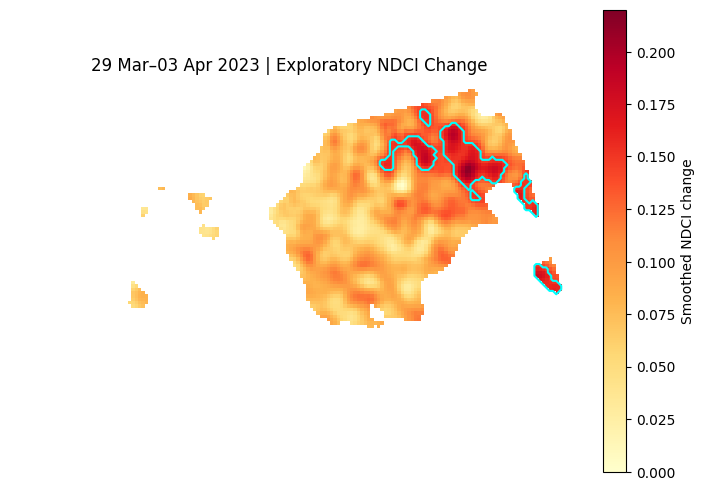

Saved outputs to: /content/AquaSpectra/results
Download these files if needed: Colab Files sidebar > content > AquaSpectra_outputs.


In [12]:
OUTPUT=str(repo_root/'results')
os.makedirs(OUTPUT,exist_ok=True)
results.to_csv(os.path.join(OUTPUT,'AquaSpectra_Monitoring_Regions.csv'),index=False)
fig,ax=plt.subplots(figsize=(9,6))
im=ax.imshow(np.ma.masked_invalid(change),cmap='YlOrRd',vmin=0,vmax=0.22)
ax.contour(final_regions.astype(int),levels=[0.5],colors='cyan',linewidths=1.5)
ax.set_title('29 Mar–03 Apr 2023 | Exploratory NDCI Change')
ax.axis('off');fig.colorbar(im,ax=ax,label='Smoothed NDCI change')
fig.savefig(os.path.join(OUTPUT,'AquaSpectra_Change_Map.png'),dpi=180,bbox_inches='tight')
plt.show()
print('Saved outputs to:',OUTPUT)
print('Download these files if needed: Colab Files sidebar > content > AquaSpectra_outputs.')

## Optional exploratory machine-learning comparison (professor suggestion)

This experiment compares the **original, unchanged NDCI 90th-percentile baseline** with Isolation Forest and K-means using the **same 3,435 valid spatial pixels** and three features: smoothed NDCI on 29 March, smoothed NDCI on 3 April, and their difference. Features are standardized. Isolation Forest uses a fixed seed and selects the same number of pixels as the baseline for a size-controlled comparison. K-means uses 2 clusters and identifies the cluster with higher mean NDCI change; its size is not forced to match the baseline.

**Important:** There are no independent biological labels. Overlap/Jaccard quantify *agreement with the baseline*, **not model accuracy or environmental validity**. Isolation Forest identifies statistical outliers, including potentially negative changes; K-means partitions feature space. Neither independently confirms chlorophyll or harmful algal blooms.


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans

ml_features = np.column_stack([before[valid_change], after[valid_change], change[valid_change]])
ml_scaled = StandardScaler().fit_transform(ml_features)
ml_baseline = priority_mask[valid_change]
ml_k = int(ml_baseline.sum())
ml_iso = IsolationForest(n_estimators=200, contamination=ml_k/len(ml_baseline), random_state=42, n_jobs=1).fit(ml_scaled)
ml_iso_scores = -ml_iso.score_samples(ml_scaled)
ml_iso_flag = np.zeros(len(ml_baseline), dtype=bool)
ml_iso_flag[np.argsort(-ml_iso_scores, kind='stable')[:ml_k]] = True
ml_kmeans = KMeans(n_clusters=2, n_init=20, random_state=42).fit(ml_scaled)
ml_high_cluster = int(np.argmax([ml_features[ml_kmeans.labels_ == j, 2].mean() for j in range(2)]))
ml_kmeans_flag = ml_kmeans.labels_ == ml_high_cluster

def comparison_row(name, selected):
    overlap = int(np.sum(selected & ml_baseline))
    union = int(np.sum(selected | ml_baseline))
    return {'Method': name, 'Selected pixels': int(selected.sum()), 'Overlap with baseline': overlap,
            'Jaccard similarity': round(overlap/union, 4),
            'Mean NDCI change': round(float(ml_features[selected,2].mean()),5)}

ml_comparison = pd.DataFrame([
    comparison_row('NDCI top-10% baseline', ml_baseline),
    comparison_row('Isolation Forest', ml_iso_flag),
    comparison_row('K-means (higher-change cluster)', ml_kmeans_flag)])
display(ml_comparison)
ml_comparison.to_csv(repo_root/'results/ML_Exploratory_Comparison.csv',index=False)


,Method,Selected pixels,Overlap with baseline,Jaccard similarity,Mean NDCI change
0,NDCI top-10% baseline,344,344,1.0000,0.16224
1,Isolation Forest,344,155,0.2908,0.11175
2,K-means (higher-change cluster),1286,344,0.2675,0.13088


## 9. ML method comparison maps
The same valid-change pixels are used for all three exploratory methods. These maps show **agreement, not accuracy**.

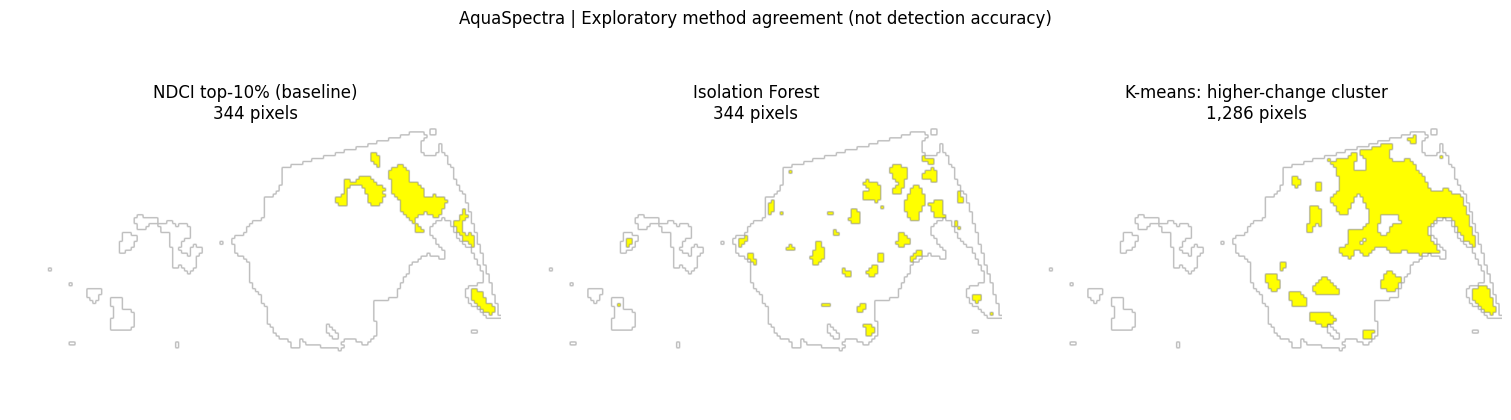

ML comparison saved under results/. Original NDCI baseline remains unchanged.


In [14]:
# Visual comparison: identical eligible pixel positions for all three methods.
iso_map = np.zeros(expected_shape, dtype=bool)
kmeans_map = np.zeros(expected_shape, dtype=bool)
iso_map[valid_change] = ml_iso_flag
kmeans_map[valid_change] = ml_kmeans_flag
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, mask, title in zip(axes, [priority_mask, iso_map, kmeans_map],
                           ['NDCI top-10% (baseline)', 'Isolation Forest', 'K-means: higher-change cluster']):
    ax.imshow(np.where(common_mask, 0.0, np.nan), cmap='Greys', vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(~mask, mask.astype(float)), cmap='autumn', vmin=0, vmax=1)
    ax.set_title(f'{title}\n{int(mask.sum()):,} pixels')
    ax.axis('off')
fig.suptitle('AquaSpectra | Exploratory method agreement (not detection accuracy)')
fig.savefig(repo_root/'results/ML_Method_Comparison_Maps.png', dpi=180, bbox_inches='tight')
plt.show()
print('ML comparison saved under results/. Original NDCI baseline remains unchanged.')
